# ISO 20414:2020 — Test 15: Social Influence on Exit Choice

A room of size 10 m x 15 m with two 1 m exits on the 15 m walls of the room (ISO 20414:2020 Figure 11). In Scenario 1, only two agents, equidistant to both exits, in the room and is free to choose between exits 1 and 2 (both exit weights are 50%). After statistics harvested for exit choice through several runs, Scenario 2 is run which inserts an additional occupant who is deterministically assigned to Exit 2.  Test is run several times again. Expected result is that the usage of Exit 2 is increased in scenario 2 for occupant 1.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 17:41 CEST


In [2]:
from pathlib import Path
import logging
logging.basicConfig(level=logging.WARNING, force=True)
logging.getLogger().setLevel(logging.WARNING)
#logging.getLogger("jupedsim_scenarios").setLevel(logging.WARNING)
#logging.getLogger("jupedsim").setLevel(logging.WARNING)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario, run_sweep

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load and Run

In [5]:
%%capture
SCENARIO_ZIP_1 = Path("scenario_files") / "Iso-15-social-influence-1.zip"
scenario_1 = load_scenario(str(SCENARIO_ZIP_1))
result_1 = run_scenario(scenario_1, seed=42)

In [6]:
print(scenario_1.summary())
walkable_1 = scenario_1.walkable_polygon

Scenario: scenario_files/Iso-15-social-influence-1.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         2
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~2
    jps-distributions_0: 2 agents


In [7]:
%%capture
SCENARIO_ZIP_2 = Path("scenario_files") / "Iso-15-social-influence-2.zip"
scenario_2 = load_scenario(str(SCENARIO_ZIP_2))
result_2 = run_scenario(scenario_2, seed=42)

In [8]:
print(scenario_2.summary())
walkable_2 = scenario_2.walkable_polygon

Scenario: scenario_files/Iso-15-social-influence-2.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         2
  Distributions: 2
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~3
    jps-distributions_0: 2 agents
    jps-distributions_1: 1 agents


## Scenario figure

Room with two exits for Scenario 1 and Scenario 2.

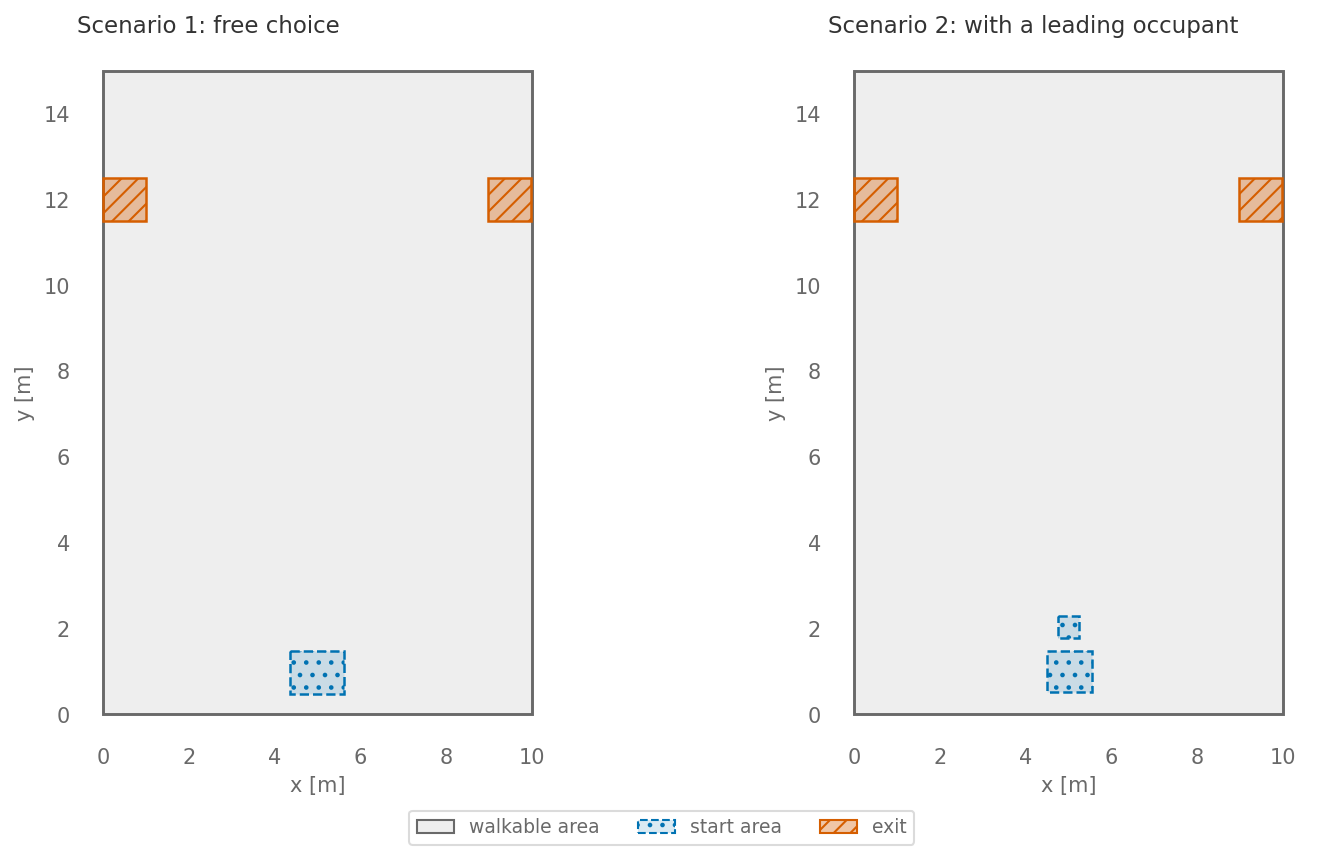

In [9]:
# Scenario geometry of each variant from the loaded ZIPs.
with plt.rc_context(VV_RC):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), layout="constrained")
    for ax, (scen, label) in zip(axes, [(scenario_1, "Scenario 1: free choice"), (scenario_2, "Scenario 2: with a leading occupant")]):
        handles = vv_draw_scenario(ax, scen)
        ax.set_title(label, loc="left")
    fig.legend(handles=handles, loc="outside lower center", ncol=3)
    plt.show()

In [10]:
def count_exit_choices(scenario, seeds, workers=4, track=None):
    sweep = run_sweep(scenario, seeds=seeds, workers=workers)
    exit_1_count = 0
    exit_2_count = 0
    unknown_count = 0
    rows = []

    for trial in sweep.trials:
        seed = trial.seed
        result = trial.result
        df_1 = result.trajectory_dataframe()

        if track == "behind":
            initial = df_1[df_1["frame"] == df_1["frame"].min()]
            tracked_ids = initial[initial["y"] < 1.5]["id"].tolist()
            final_rows = [
                df_1[df_1["id"] == agent_id].sort_values("frame").iloc[-1]
                for agent_id in tracked_ids
            ]
        elif track == "front":
            initial = df_1[df_1["frame"] == df_1["frame"].min()]
            tracked_ids = initial[initial["y"] >= 1.5]["id"].tolist()
            final_rows = [
                df_1[df_1["id"] == agent_id].sort_values("frame").iloc[-1]
                for agent_id in tracked_ids
            ]
        else:
            final_rows = [df_1.sort_values("frame").iloc[-1]]

        for last in final_rows:
            if last["y"] >= 11.0:
                if last["x"] <= 1.5:
                    chosen_exit = "exit_1"
                    exit_1_count += 1
                elif last["x"] >= 8.5:
                    chosen_exit = "exit_2"
                    exit_2_count += 1
                else:
                    chosen_exit = "unknown"
                    unknown_count += 1
            else:
                chosen_exit = "no exit"
                unknown_count += 1

            rows.append({
                "seed": seed,
                "id": int(last["id"]),
                "x_final": last["x"],
                "y_final": last["y"],
                "chosen_exit": chosen_exit,
            })

    sweep.cleanup()

    exit_choices = pd.DataFrame(rows)
    total = len(exit_choices)

    return {
        "exit_1_count": exit_1_count,
        "exit_2_count": exit_2_count,
        "unknown_count": unknown_count,
        "exit_1_fraction": exit_1_count / total,
        "exit_2_fraction": exit_2_count / total,
        "unknown_fraction": unknown_count / total,
        "rows": exit_choices,
    }

## Scenario 1 Statistics

In [11]:
%%capture
run_1a = count_exit_choices(scenario_1, seeds=range(1, 4001), workers=4)
run_1b = count_exit_choices(scenario_1, seeds=range(4001, 8001), workers=4)

In [12]:
comparison = pd.DataFrame([
    {
        "exit": "exit_1",
        "run_1a_count": run_1a["exit_1_count"],
        "run_1b_count": run_1b["exit_1_count"],
        "run_1a_fraction": run_1a["exit_1_fraction"],
        "run_1b_fraction": run_1b["exit_1_fraction"],
    },
    {
        "exit": "exit_2",
        "run_1a_count": run_1a["exit_2_count"],
        "run_1b_count": run_1b["exit_2_count"],
        "run_1a_fraction": run_1a["exit_2_fraction"],
        "run_1b_fraction": run_1b["exit_2_fraction"],
    },
])

comparison

,exit,run_1a_count,run_1b_count,run_1a_fraction,run_1b_fraction
0,exit_1,1894,1899,0.4735,0.47475
1,exit_2,2106,2101,0.5265,0.52525


## Acceptance - Scenario 1

In [13]:
assert abs(run_1a["exit_1_fraction"] - run_1b["exit_1_fraction"]) * 100 <= 1.0
assert abs(run_1a["exit_2_fraction"] - run_1b["exit_2_fraction"]) * 100 <= 1.0

## Scenario 2 Statistics

In [14]:
scenario_2_front = count_exit_choices(
    scenario_2,
    seeds=range(1, 4001),
    workers=4,
    track="front",
)
result_front = pd.DataFrame([{
    "exit": "exit_1",
    "count": scenario_2_front["exit_1_count"],
    "fraction": scenario_2_front["exit_1_fraction"]
}, {
    "exit": "exit_2",
    "count": scenario_2_front["exit_2_count"],
    "fraction": scenario_2_front["exit_2_fraction"]
}])

result_front

,exit,count,fraction
0,exit_1,0,0.0
1,exit_2,4000,1.0


In [15]:
scenario_2_behind = count_exit_choices(
    scenario_2,
    seeds=range(1, 4001),
    workers=4,
    track="behind",
)

result_behind = pd.DataFrame([{
    "exit": "exit_1",
    "count": scenario_2_behind["exit_1_count"],
    "fraction": scenario_2_behind["exit_1_fraction"]
}, {
    "exit": "exit_2",
    "count": scenario_2_behind["exit_2_count"],
    "fraction": scenario_2_behind["exit_2_fraction"]
}])

result_behind

,exit,count,fraction
0,exit_1,4000,0.5
1,exit_2,4000,0.5


## Plot Trajectories

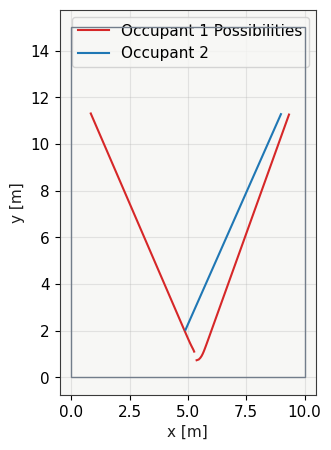

In [16]:
df_2 = result_2.trajectory_dataframe()
initial = df_2[df_2["frame"] == df_2["frame"].min()]
occupant_1_ids = initial[initial["y"] < 1.5]["id"].tolist()
occupant_2_ids = initial[initial["y"] >= 1.5]["id"].tolist()
df_plot = df_2[["id", "frame", "x", "y"]].copy()
df_plot = df_plot[df_plot["id"].isin(occupant_1_ids + occupant_2_ids)]

traj = pedpy.TrajectoryData(
    df_plot[["id", "frame", "x", "y"]].copy(),
    frame_rate=result_2.frame_rate,
)
wa = pedpy.WalkableArea(walkable_2)

fig, ax = plt.subplots()

pedpy.plot_walkable_area(walkable_area=wa, axes=ax)

for agent_id, sub in df_plot.sort_values(["id", "frame"]).groupby("id"):
    if agent_id in occupant_1_ids:
        color = "tab:red"
    else:
        color = "tab:blue"

    ax.plot(sub["x"], sub["y"], color=color)

ax.plot([], [], color="tab:red", label="Occupant 1 Possibilities")
ax.plot([], [], color="tab:blue", label="Occupant 2")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.show()

## Result figure

Exit-2 share of the occupant behind and of the occupant ahead in Scenario 2, against the free-choice baseline of Scenario 1.

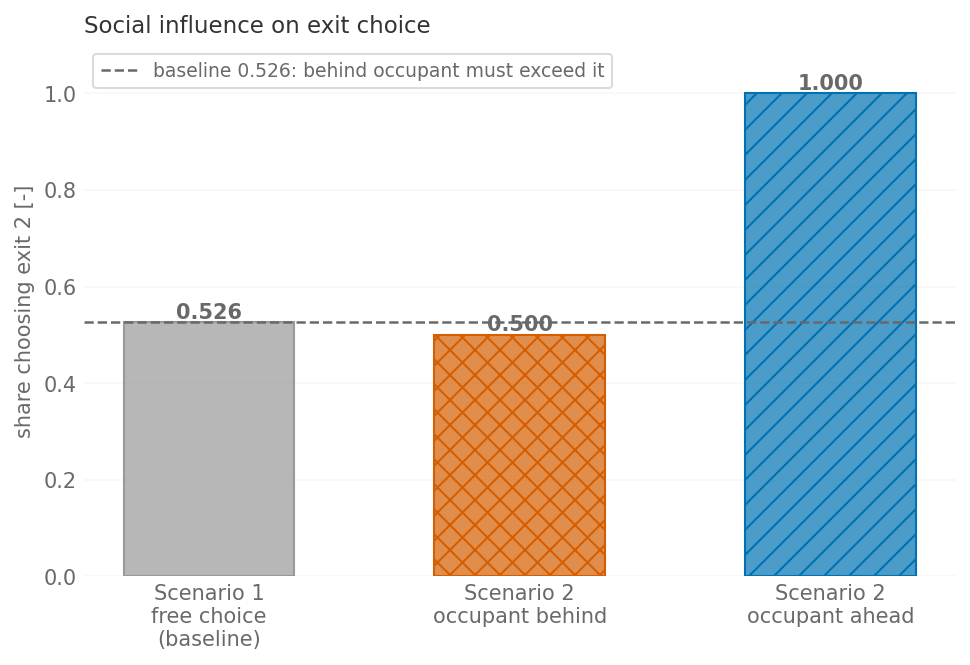

In [17]:
# Exit-2 share of the occupant behind against the Scenario 1 baseline (documented failure).
baseline = run_1a["exit_2_fraction"]
labels = ["Scenario 1\nfree choice\n(baseline)", "Scenario 2\noccupant behind", "Scenario 2\noccupant ahead"]
values = [baseline, scenario_2_behind["exit_2_fraction"], scenario_2_front["exit_2_fraction"]]
colors = ["#999999", VV_RED, VV_BLUE]
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    bars = ax.bar(labels, values, color=[to_rgba(c, 0.7) for c in colors], edgecolor=colors, width=0.55)
    for bar, hatch in zip(bars, ["", "xx", "//"]):
        bar.set_hatch(hatch)
    ax.bar_label(bars, fmt="%.3f", color="dimgrey", fontweight="semibold")
    ax.axhline(baseline, color="dimgrey", ls="--", lw=1.2, label=f"baseline {baseline:.3f}: behind occupant must exceed it")
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("share choosing exit 2 [-]")
    ax.set_title("Social influence on exit choice", loc="left")
    ax.legend(loc="upper left")
    ax.grid(axis="x", visible=False)
    plt.show()

## Acceptance - FAIL

This assertion FAILS. It is documented as a model limitation: the route assignment is static, so every seed yields a 1:1 exit split for the behind group. Measured: behind-group exit-2 fraction 0.500 vs Scenario 1 baseline 0.519 (seeds 1-4000).

In [18]:
assert scenario_2_front["exit_1_count"] == 0
assert scenario_2_front["exit_2_count"] == len(scenario_2_front["rows"])
try:
    assert scenario_2_behind["exit_2_fraction"] > run_1a["exit_2_fraction"]
except AssertionError:
    print(f"FAIL (documented model limitation): behind-group exit_2_fraction {scenario_2_behind['exit_2_fraction']:.3f} does not exceed the Scenario 1 baseline {run_1a['exit_2_fraction']:.3f}. The 1:1 exit split is a documented model limitation.")
else:
    raise AssertionError("XPASS: expected failure did not occur; review the model limitation note.")


FAIL (documented model limitation): behind-group exit_2_fraction 0.500 does not exceed the Scenario 1 baseline 0.526. The 1:1 exit split is a documented model limitation.


The current route assignment is static, so ISO 15 social influence is not reproduced. Model fails the test.